<a href="https://colab.research.google.com/github/cleberfmodesto/classificacao_xgboost/blob/main/Atividades/Carregar_Dados.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Colab-F9AB00?labelColor=F9AB00&logo=googlecolab&logoColor=white" alt="Abrir no Colab"/></a> <a href="https://github.com/cleberfmodesto/classificacao_xgboost/blob/main/Atividades/Carregar_Dados.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-GitHub-0969DA?labelColor=0969DA&logo=github&logoColor=white" alt="Abrir GitHub"/></a> <a href="https://github.com/codespaces/new?repo=cleberfmodesto/classificacao_xgboost&ref=main" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Codespaces-1F883D?labelColor=1F883D&logo=github&logoColor=white" alt="Abrir no Codespaces"/></a>

# Carregamento dos Dados de Potabilidade da Água

Este notebook carrega o conjunto de dados diretamente de uma URL e faz uma inspeção inicial.

# Carregamento dos Dados de Potabilidade da Água

Este notebook carrega o conjunto de dados diretamente de uma URL e faz uma inspeção inicial.

## 1. Importação das Bibliotecas Necessárias

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Carregamento dos Dados a partir da URL

O arquivo CSV é lido diretamente da URL e armazenado no DataFrame `df`.

In [ ]:
url = "https://raw.githubusercontent.com/cleberfmodesto/classificacao_xgboost/main/Dados/water_potability.csv"
df = pd.read_csv(url)

print("Dados carregados com sucesso.")

Dados carregados com sucesso.


## 3. Visualização Inicial dos Dados

Abaixo, conferimos as primeiras observações, o tamanho do conjunto e o tipo de cada coluna.

In [3]:
display(df.head())

print(f"Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.dtypes.to_frame(name="tipo de dado"))

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


Dimensões: 3276 linhas e 10 colunas


,tipo de dado
ph,float64
Hardness,float64
Solids,float64
Chloramines,float64
Sulfate,float64
Conductivity,float64
Organic_carbon,float64
Trihalomethanes,float64
Turbidity,float64
Potability,int64


## 4. Análise e Tratamento dos Dados

Vamos verificar valores ausentes, registros duplicados e a distribuição da variável-alvo `Potability`. Os valores ausentes serão imputados dentro do pipeline, usando apenas os dados de treino.

In [6]:
coluna_alvo = "Potability"

resumo_ausentes = df.isna().sum().sort_values(ascending=False)
resumo_ausentes = resumo_ausentes[resumo_ausentes > 0].to_frame(name="valores ausentes")
if resumo_ausentes.empty:
    print("Nenhum valor ausente encontrado.")
else:
    display(resumo_ausentes)

print(f"Registros duplicados: {df.duplicated().sum()}")
display(df[coluna_alvo].value_counts().sort_index().rename(index={0: "Não potável (0)", 1: "Potável (1)"}).to_frame(name="quantidade"))

,valores ausentes
Sulfate,781
ph,491
Trihalomethanes,162


Registros duplicados: 0


,quantidade
Potability,
Não potável (0),1998
Potável (1),1278


## 5. Criação de X e y e Separação em Treino e Teste

`X` contém as características da água e `y` indica a potabilidade. A divisão estratificada preserva a proporção das classes nos dois conjuntos.

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[coluna_alvo])
y = df[coluna_alvo]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Treino: {X_treino.shape[0]} amostras")
print(f"Teste: {X_teste.shape[0]} amostras")

Treino: 2620 amostras
Teste: 656 amostras


## 6. Importação do XGBoost, Treinamento e Previsões

O pipeline imputa valores ausentes pela mediana e, em seguida, treina o classificador XGBoost.

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

modelo = make_pipeline(
    SimpleImputer(strategy="median"),
    XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
)

modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)
probabilidades_potavel = modelo.predict_proba(X_teste)[:, 1]
print("Modelo treinado e previsões geradas.")

Modelo treinado e previsões geradas.


## 7. Avaliação do Modelo

O relatório mostra precisão, sensibilidade e F1-score por classe. A AUC é calculada a partir das probabilidades previstas; a matriz de confusão compara rótulos reais e previstos.

                 precision    recall  f1-score   support

Não potável (0)       0.66      0.84      0.74       400
    Potável (1)       0.57      0.32      0.41       256

       accuracy                           0.64       656
      macro avg       0.62      0.58      0.58       656
   weighted avg       0.63      0.64      0.61       656

ROC AUC: 0.656


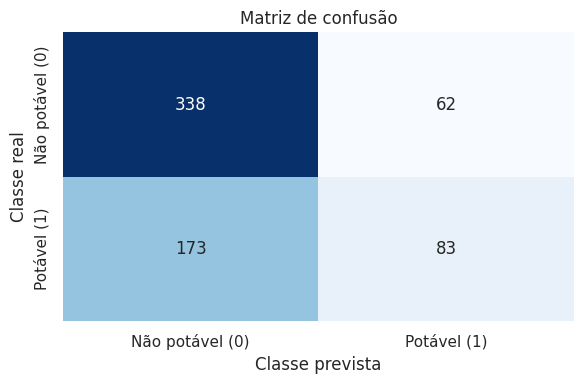

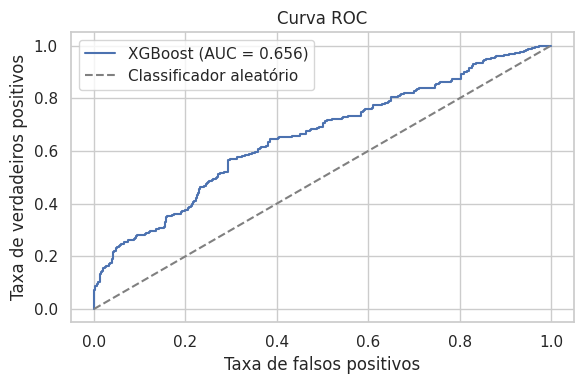

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

print(classification_report(
    y_teste,
    previsoes,
    labels=[0, 1],
    target_names=["Não potável (0)", "Potável (1)"],
    zero_division=0,
))

roc_auc = roc_auc_score(y_teste, probabilidades_potavel)
print(f"ROC AUC: {roc_auc:.3f}")

matriz_confusao = confusion_matrix(y_teste, previsoes, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(
    matriz_confusao,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Não potável (0)", "Potável (1)"],
    yticklabels=["Não potável (0)", "Potável (1)"],
)
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão")
plt.tight_layout()
plt.show()

falso_positivo, verdadeiro_positivo, _ = roc_curve(y_teste, probabilidades_potavel)
plt.figure(figsize=(6, 4))
plt.plot(falso_positivo, verdadeiro_positivo, label=f"XGBoost (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Classificador aleatório")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Resumo Visual dos Resultados

A tabela e o gráfico abaixo comparam precisão, sensibilidade e F1-score para cada classe.

,Precisão,Sensibilidade,F1-score
Não potável (0),0.661,0.845,0.742
Potável (1),0.572,0.324,0.414


ROC AUC geral: 0.656


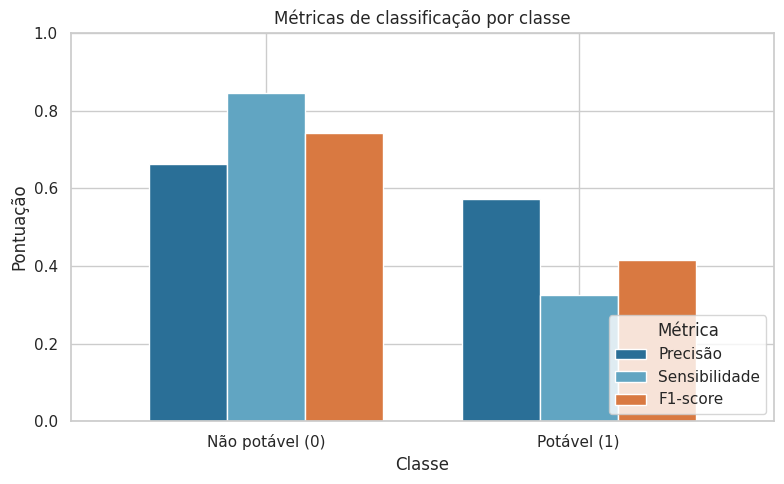

Acurácia geral: 0.642


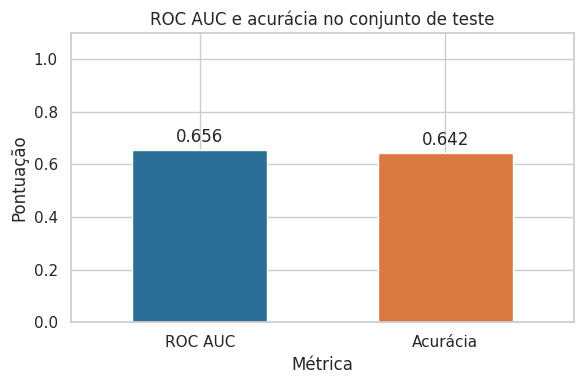

In [13]:
from sklearn.metrics import accuracy_score

relatorio_metricas = classification_report(
    y_teste,
    previsoes,
    labels=[0, 1],
    target_names=["Não potável (0)", "Potável (1)"],
    output_dict=True,
    zero_division=0,
)
metricas_por_classe = pd.DataFrame(relatorio_metricas).T.loc[
    ["Não potável (0)", "Potável (1)"],
    ["precision", "recall", "f1-score"],
]
metricas_por_classe = metricas_por_classe.rename(
    columns={"precision": "Precisão", "recall": "Sensibilidade", "f1-score": "F1-score"}
)

display(metricas_por_classe.round(3))
print(f"ROC AUC geral: {roc_auc:.3f}")

ax = metricas_por_classe.plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    color=["#2a6f97", "#61a5c2", "#d97941"],
    width=0.75,
)
ax.set_title("Métricas de classificação por classe")
ax.set_xlabel("Classe")
ax.set_ylabel("Pontuação")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Métrica", loc="lower right")
plt.tight_layout()
plt.show()

acuracia = accuracy_score(y_teste, previsoes)
metricas_gerais = pd.Series({"ROC AUC": roc_auc, "Acurácia": acuracia})
print(f"Acurácia geral: {acuracia:.3f}")

ax = metricas_gerais.plot(
    kind="bar",
    figsize=(6, 4),
    ylim=(0, 1.1),
    color=["#2a6f97", "#d97941"],
    width=0.55,
)
ax.set_title("ROC AUC e acurácia no conjunto de teste")
ax.set_xlabel("Métrica")
ax.set_ylabel("Pontuação")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for barra in ax.patches:
    ax.annotate(
        f"{barra.get_height():.3f}",
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
    )
plt.tight_layout()
plt.show()

## 9. Gráfico de Correlação

A matriz de correlação de Pearson resume associações lineares entre as variáveis numéricas, incluindo `Potability`. Correlação não implica causalidade.

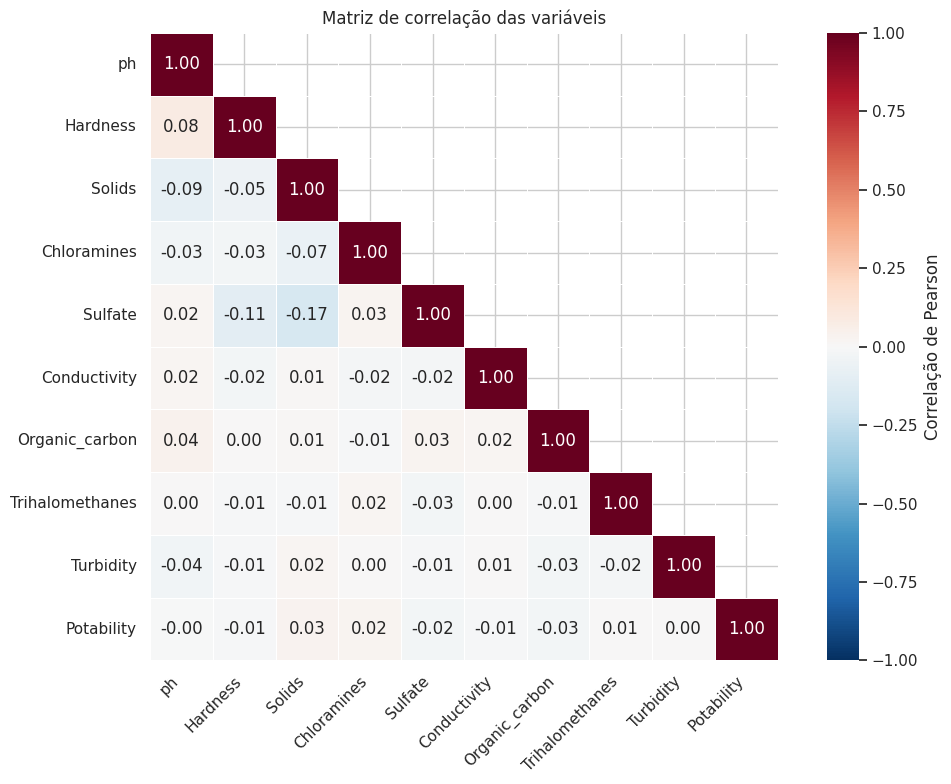

In [12]:
matriz_correlacao = df.corr(numeric_only=True)
mascara_superior = np.triu(np.ones_like(matriz_correlacao, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    matriz_correlacao,
    mask=mascara_superior,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlação de Pearson"},
    ax=ax,
)
ax.set_title("Matriz de correlação das variáveis")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()